Source Node: 532209018, Target Node: 99351404
Length (miles): 5.579681980193369
Energy consumed (kWh): 2.130434173677432


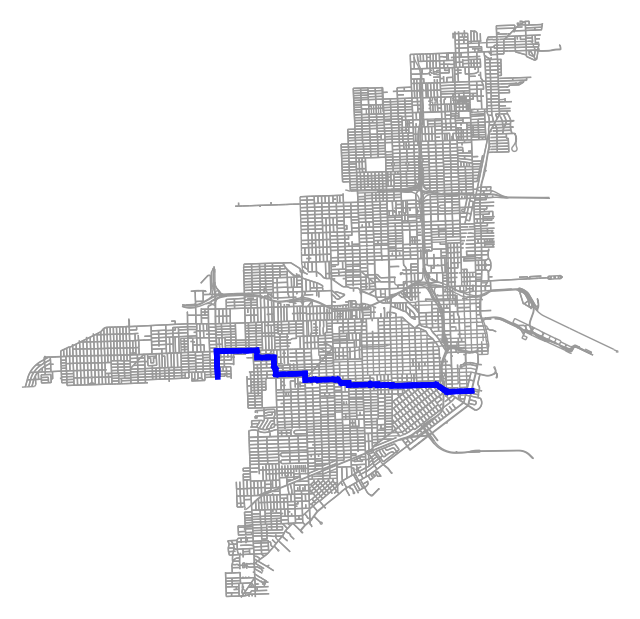

In [5]:
import networkx as nx
import osmnx as ox
import numpy as np
import matplotlib.pyplot as plt
from shapely.geometry import LineString

# road network of Miami, FL
place_name = "Miami, Florida, USA"
graph = ox.graph_from_place(place_name, network_type="drive")

# use graph.copy for computation
G = graph.copy()

# source and target by latitude and longitude
source_lat, source_lon = 25.7617, -80.1918  # downtown Miami somewhere
target_lat, target_lon = 25.758949, -80.262994  # somewhere in Coral Gables

source_node = ox.nearest_nodes(graph, X=source_lon, Y=source_lat)
target_node = ox.nearest_nodes(graph, X=target_lon, Y=target_lat)

print(f"Source Node: {source_node}, Target Node: {target_node}")

if not nx.has_path(G, source_node, target_node):
    print("No path exists between source and target. Exiting.")
    exit()

# Dijkstra path calculation (shortest path by distance)
shortest_path = nx.shortest_path(
    G, source=source_node, target=target_node, weight='length'
)

path_length_meters = sum(
    G[u][v][0]['length'] for u, v in zip(shortest_path[:-1], shortest_path[1:])
)
path_length_miles = path_length_meters / 1609.34

print(f"Length (miles): {path_length_miles}")

# energy consumption: kWh/mi = 0.38182100770306 (from data exploration)
energy_consumed = path_length_miles * 0.38182
print(f"Energy consumed (kWh): {energy_consumed}")

# visualize path on map
fig, ax = ox.plot_graph(G, node_size=0, bgcolor='white', show=False, close=False)

for u, v in zip(shortest_path[:-1], shortest_path[1:]):
    edge = G[u][v][0]
    if 'geometry' in edge:
        line = edge['geometry']
    else:
        line = LineString([(G.nodes[u]['x'], G.nodes[u]['y']),
                           (G.nodes[v]['x'], G.nodes[v]['y'])])
    ax.plot(*line.xy, linewidth=4, color='blue')
plt.show()
